# 00 — Getting started: configuration to received OFDM grid

**Purpose.** Walk through the framework's normal lifecycle: load and validate a
configuration, register a model, sample a reusable realization, transform it, and
apply it to a signal. The small assertions double as manual regression checks.

This notebook uses PyTorch on CPU with double precision. Change the seed or grid
dimensions in the parameter cell to explore, but recreate the random stream when
you want exact replay within the same backend.

In [5]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else start
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "configs").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from a Channel Dataset repository checkout")


def as_numpy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)


ROOT = find_repo_root()
SOURCE_DIRECTORY = str(ROOT / "src")
if SOURCE_DIRECTORY not in sys.path:
    sys.path.insert(0, SOURCE_DIRECTORY)

from channel_dataset.core import ExecutionContext

execution = ExecutionContext("torch", "double", "cpu")
backend = execution.array_backend
print(f"Repository: {ROOT.name} | backend={execution.backend} | precision={execution.precision}")

Repository: Channel_Dataset | backend=torch | precision=double


## 1. Load a typed configuration and construct the registered model

Configuration parsing is the boundary between external YAML and typed domain
code. `model_digest` identifies the resolved physical model; execution settings
such as backend and seed do not change it.

In [7]:
from channel_dataset.channels.wireless.fading import register_rayleigh_model
from channel_dataset.config import load_config
from channel_dataset.registry import ModelRegistry

envelope = load_config(ROOT / "configs/wireless/rayleigh_block_fading.yaml")
registry = ModelRegistry()
register_rayleigh_model(registry)
model = registry.create(envelope)

print("model:", f"{envelope.family}/{envelope.name}")
print("resolved parameters:", dict(envelope.parameters))
print("model digest:", envelope.model_digest[:16] + "…")

model: wireless/rayleigh_block_fading
resolved parameters: {'num_rx': 1, 'num_rx_antennas': 2, 'num_tx': 1, 'num_tx_antennas': 2, 'average_power_linear': 1.0}
model digest: 0f43810b559a8ca3…


## 2. Sample a reusable channel impulse response

The canonical CIR axes are
`[batch, rx, rx_antenna, tx, tx_antenna, path, time]`.
Randomness is injected through the request; calling `realize` never touches global
NumPy or PyTorch random state.

In [8]:
from channel_dataset.channels.wireless import ChannelSamplingRequest

BATCH_SIZE = 2
TIME_SAMPLES = 8
SAMPLE_RATE_HZ = 15_360_000.0
SEED = 20260923


def make_request(seed: int = SEED):
    return ChannelSamplingRequest(
        batch_size=BATCH_SIZE,
        num_time_samples=TIME_SAMPLES,
        sampling_frequency_hz=SAMPLE_RATE_HZ,
        execution=execution,
        random_stream=execution.random_stream(seed),
        request_id="notebook-getting-started",
    )


cir = model.realize(make_request())
replay = model.realize(make_request())

assert cir.shape == (2, 1, 2, 1, 2, 1, 8)
assert torch.equal(cir.coefficients, replay.coefficients)
assert torch.isfinite(cir.coefficients).all()
assert cir.metadata.config_digest == envelope.model_digest

print("CIR shape:", cir.shape)
print("path delays (s):", as_numpy(cir.delays_s[0, 0, 0]))
print("root seed:", cir.metadata.root_seed)
print("seeded replay: exact")

CIR shape: (2, 1, 2, 1, 2, 1, 8)
path delays (s): [0.]
root seed: None
seeded replay: exact


## 3. Convert to OFDM and apply the response

The transmit grid axes are `[batch, tx, tx_antenna, symbol, subcarrier]`.
`apply_ofdm` sums the transmitter and transmit-antenna axes and returns
`[batch, rx, rx_antenna, symbol, subcarrier]`. Noise is intentionally separate.

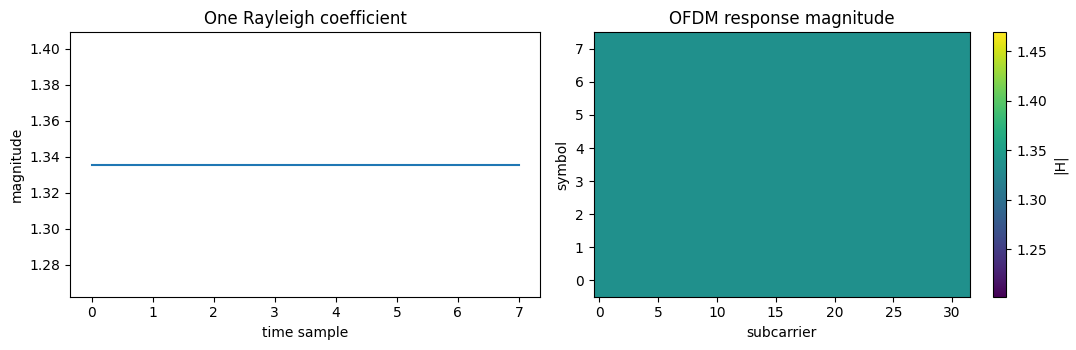

received grid shape: (2, 1, 2, 8, 32)


In [9]:
from channel_dataset.channels.wireless.operators import apply_ofdm
from channel_dataset.channels.wireless.transforms import (
    cir_to_ofdm,
    subcarrier_frequencies,
)

frequencies = subcarrier_frequencies(32, 15_000.0, execution)
response = cir_to_ofdm(cir, frequencies)
transmitted = backend.ones(
    (BATCH_SIZE, 1, 2, TIME_SAMPLES, 32),
    dtype=execution.complex_dtype,
    device=execution.device,
)
received = apply_ofdm(response, transmitted)

assert response.shape == (2, 1, 2, 1, 2, 8, 32)
assert backend.shape(received) == (2, 1, 2, 8, 32)
assert torch.isfinite(received).all()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(as_numpy(torch.abs(cir.coefficients[0, 0, 0, 0, 0, 0])))
axes[0].set(title="One Rayleigh coefficient", xlabel="time sample", ylabel="magnitude")
image = axes[1].imshow(
    as_numpy(torch.abs(response.coefficients[0, 0, 0, 0, 0])),
    aspect="auto",
    origin="lower",
)
axes[1].set(title="OFDM response magnitude", xlabel="subcarrier", ylabel="symbol")
fig.colorbar(image, ax=axes[1], label="|H|")
fig.tight_layout()
plt.show()
print("received grid shape:", tuple(received.shape))

## Manual check and next experiments

- Confirm the single Rayleigh path is constant across time and flat across subcarriers.
- Change `SEED`; the coefficients should change while shapes and digest stay fixed.
- Change the YAML profile or an envelope override; the physical-model digest should change.
- Try `ExecutionContext("numpy", "double", "cpu")` and compare contracts, not stochastic samples.